### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_QOUQAYNGCUKK


## Preparations

### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy import ndimage as ndi
from nptdms import TdmsFile
from scipy import signal
import h5py
import glob, os
import cv2
import seaborn as sns
from roifile import roiread
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator
import matplotlib.gridspec as gridspec

In [4]:
from matplotlib import font_manager
import matplotlib as mpl
font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [5]:
import sys
sys.path.append("/home/t/tomoyuki-mano1/projects/OL_calcium")
from calfuncs.io import read_sync_ttl
from calfuncs.drg import compute_osi, compute_dsi, compute_simple_oi, get_ett2, \
                         plot_grating_response, plot_polar_graph, plot_grating_response_combined,\
                         FigParams, compute_qi, compute_qi2, bootstrap_selectivity, bootstrap_selectivity2

### Load data

In [6]:
database = [
    {
        "name": "20250317_rec2",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250317_rec2/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec2/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec2/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250317_rec4",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250317_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec4/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec4",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250318_rec4/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec4/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec4/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250318_rec6",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250318_rec6/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec6/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250318_squid_cal520/2P/rec6/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250124_rec7",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250124_rec7/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250124_squid_cal520/2P/rec7/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250124_squid_cal520/2P/rec7/run2/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250124_rec9",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250124_rec9/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250124_squid_cal520/2P/rec9/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250124_squid_cal520/2P/rec9/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
    {
        "name": "20250129_rec6",
        "resp_table": "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/20250129_rec6/response_table.hdf5",
        "roifile": "/bucket/ReiterU/OLdev/experiments/20250129_squid_cal520/2P/rec6/ROI_yutaka_renamed.zip",
        "template_img": "/bucket/ReiterU/OLdev/experiments/20250129_squid_cal520/2P/rec6/run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"
    },
]

In [7]:
R, E = [], []
for (k, d) in enumerate(database):
    with pd.HDFStore(d["resp_table"], mode='r') as store:
        r = store["R"]
        e = store["E"]
    r["recording"] = k
    r["cell_id"] = r["neuron"] + k * 1000
    e["recording"] = k
    e = e.reset_index().set_index(["recording", "neuron", "session", "trial", "ori", "sf", "tf", "time"])
    R.append(r)
    E.append(e)
R = pd.concat(R)
R.reset_index(drop=True, inplace=True)
E = pd.concat(E)

In [8]:
# remap angles
mapping = {
    0: 180,
    45: 135,
    90: 90,
    135: 45,
    180: 0,
    225: 315,
    270: 270,
    315: 225
}
R.loc[:, 'ang_osi'] = R['ang_osi'].replace(mapping)
R.loc[:, 'ang_dsi'] = R['ang_dsi'].replace(mapping)
E = E.reset_index()
E.loc[:, "ori"] = E["ori"].replace(mapping)
E = E.reset_index().set_index(["recording", "neuron", "session", "trial", "ori", "sf", "tf", "time"])

In [9]:
display(R)

,neuron,session,qi,osi,resp_osi,ang_osi,pval_osi,flag_osi,dsi,resp_dsi,ang_dsi,pval_dsi,flag_dsi,recording,cell_id
0,0,0,0.062074,0.158078,"[-0.006872337479989295, 0.0025648026097431914,...",135,0.7502,False,0.243625,"[-0.006872337479989295, 0.0025648026097431914,...",315,0.4880,False,0,0
1,0,1,0.069870,0.211767,"[-0.011061263565364679, -0.02065915136773587, ...",45,0.5175,False,0.332019,"[-0.011061263565364679, -0.02065915136773587, ...",45,0.1802,False,0,0
2,0,2,0.063927,0.257264,"[0.002460870924136771, -0.006910377709095997, ...",45,0.6601,False,0.327178,"[0.002460870924136771, -0.006910377709095997, ...",45,0.4537,False,0,0
3,1,0,0.134465,0.138525,"[0.06312615740967671, 0.07955013337605286, 0.0...",45,0.7341,False,0.461869,"[0.06312615740967671, 0.07955013337605286, 0.0...",225,0.0164,True,0,1
4,1,1,0.131095,0.219974,"[0.06450804627566584, 0.0170263655861327, 0.05...",45,0.4972,False,0.407036,"[0.06450804627566584, 0.0170263655861327, 0.05...",225,0.0771,False,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2080,109,1,0.065934,0.259592,"[-0.007470427837913148, -0.0021262350751314572...",45,0.3890,False,0.227992,"[-0.007470427837913148, -0.0021262350751314572...",225,0.4744,False,6,6109
2081,109,2,0.052957,0.197671,"[-0.024239867500301104, -0.01942999618730082, ...",90,0.5814,False,0.119269,"[-0.024239867500301104, -0.01942999618730082, ...",90,0.8288,False,6,6109
2082,110,0,0.066175,0.193787,"[-0.006791223084932517, -0.0008476654563029141...",135,0.6622,False,0.057282,"[-0.006791223084932517, -0.0008476654563029141...",315,0.9631,False,6,6110
2083,110,1,0.064734,0.060683,"[-0.013915796737608573, -0.0001285973209037048...",45,0.9525,False,0.169712,"[-0.013915796737608573, -0.0001285973209037048...",225,0.6972,False,6,6110


In [10]:
display(E)

index         y
recording neuron session trial ori sf      tf time                     
0         0      0       0     180 0.00425 3  -2000         0 -0.105205
                                              -1950         1 -0.061834
                                              -1900         2 -0.014670
                                              -1850         3 -0.071981
                                              -1800         4 -0.043125
...                                                       ...       ...
6         110    2       17    225 0.00850 3   4250  39031195 -0.009029
                                               4300  39031196 -0.044983
                                               4350  39031197  0.004565
                                               4400  39031198  0.041497
                                               4450  39031199  0.029481

[39031200 rows x 2 columns]

### Classify types

In [11]:
# 0 = no response
# 1 = only DoLP
# 2 = only pol light
# 3 = DoLP & pol light
# 4 = only unpol light
# 5 = DoLP & unpol light
# 6 = pol light & unpol light
# 7 = all

for n in R["cell_id"].unique().tolist():
    df = R[(R["cell_id"] == n) & (R["flag_dsi"])]
    p1 =(df["session"] == 0).any()
    p2 =(df["session"] == 1).any()
    p3 =(df["session"] == 2).any()
    R.loc[R["cell_id"] == n, "ds_type"] = 4 * p1 + 2 * p2 + 1 * p3

for n in R["cell_id"].unique().tolist():
    df = R[(R["cell_id"] == n) & (R["flag_osi"])]
    p1 =(df["session"] == 0).any()
    p2 =(df["session"] == 1).any()
    p3 =(df["session"] == 2).any()
    R.loc[R["cell_id"] == n, "os_type"] = 4 * p1 + 2 * p2 + 1 * p3

In [56]:
def show_pie(df, which):
    types = [0, 1, 2, 4, 3, 5, 6, 7]
    labels = ["none", "only DoLP",
              "only pol light", "only unpol light",
              "DoLP & pol light", "DoLP & unpol light",
              "pol light & unpol light", "all"]
    num_elements = []
    total_elements = df["cell_id"].unique().size
    for i in types:
        if which == "ds":
            match = df[df["ds_type"] == i]["cell_id"].unique()
        elif which == "os":
            match = df[df["os_type"] == i]["cell_id"].unique()
        num_elements.append(match.size)
    print("Types:", labels)
    print("# of cells:", num_elements)
    print("Percentage:", [e/total_elements*100 for e in num_elements])
    
    fig, ax = plt.subplots(figsize=(2.,2.), dpi=300)
    
    # Custom autopct function
    def autopct_threshold(pct, threshold=1):
        return f'{pct:.1f}%' if pct >= threshold else ''
    
    wedges, texts, autotexts = ax.pie(
        num_elements, labels=None,
        autopct=lambda pct: autopct_threshold(pct, threshold=1),
        startangle=90, counterclock=False,
        pctdistance=1.1, textprops={'size': 6}
    )
    ax.legend(
        wedges, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, -0.2),  # Adjust vertical position
        ncol=4,  # Two rows for 8 items
        prop={'size': 6}
    )
    ax.axis('equal')
    if which == "ds":
        ax.set_title("DS")
    elif which == "os":
        ax.set_title("OS")
    plt.show()

def show_two_angles(df, which="ds", figsavename=None):
    if which == "ds":
        match = df[df["ds_type"].isin([6, 7])]["cell_id"].unique()
    elif which == "os":
        match = df[df["os_type"].isin([6, 7])]["cell_id"].unique()
    df_filtered = df[df["cell_id"].isin(match)]

    if which == "ds":
        ang0 = df_filtered[df_filtered["session"] == 0]["ang_dsi"]
        ang1 = df_filtered[df_filtered["session"] == 1]["ang_dsi"]
    elif which == "os":
        ang0 = df_filtered[df_filtered["session"] == 0]["ang_osi"]
        ang1 = df_filtered[df_filtered["session"] == 1]["ang_osi"]
    
    # Compute 2D histogram
    if which == "ds":
        angles = np.array([0, 45, 90, 135, 180, 225, 270, 315])
        edges = np.arange(-22.5, 360, 45)  # [-22.5, 22.5, 67.5, ..., 337.5]
    elif which == "os":
        angles = np.array([0, 45, 90, 135, 180])
        edges = np.arange(-22.5, 225, 45)  # [-22.5, 22.5, 67.5, ..., 337.5]
    H, xedges, yedges = np.histogram2d(ang0, ang1, bins=[edges, edges])
    
    fig, ax = plt.subplots(figsize=(2., 2.), dpi=300)
    c = ax.pcolormesh(xedges, yedges, H.T, cmap='viridis', edgecolors='k')
    cax = ax.inset_axes([1.04, 0.2, 0.05, 0.6])
    cbar = fig.colorbar(c, cax=cax, pad=0.04, label="counts")
    
    ax.set_xticks(angles[::2])
    ax.set_yticks(angles[::2])
    if which == "ds":
        ax.set_xlabel('pref. direction 1')
        ax.set_ylabel('pref. direction 2')
    else:
        ax.set_xlabel('pref. orientation 1')
        ax.set_ylabel('pref. orientation 2')
    ax.set_aspect('equal')
    plt.tight_layout()
    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

def show_two_angles_2(df, which="ds", figsavename=None):
    match = df[df["ds_type"].isin([3,5,7])]["cell_id"].unique()
    df_filtered = df[df["cell_id"].isin(match)]

    if which == "ds":
        ang0 = df_filtered[df_filtered["session"] == 0]["ang_dsi"]
        ang1 = df_filtered[df_filtered["session"] == 1]["ang_dsi"]
    elif which == "os":
        ang0 = df_filtered[df_filtered["session"] == 0]["ang_osi"]
        ang1 = df_filtered[df_filtered["session"] == 1]["ang_osi"]
    
    # Compute 2D histogram
    if which == "ds":
        angles = np.array([0, 45, 90, 135, 180, 225, 270, 315])
        edges = np.arange(-22.5, 360, 45)  # [-22.5, 22.5, 67.5, ..., 337.5]
    elif which == "os":
        angles = np.array([0, 45, 90, 135, 180])
        edges = np.arange(-22.5, 225, 45)  # [-22.5, 22.5, 67.5, ..., 337.5]
    H, xedges, yedges = np.histogram2d(ang0, ang1, bins=[edges, edges])
    
    fig, ax = plt.subplots(figsize=(2., 2.), dpi=300)
    c = ax.pcolormesh(xedges, yedges, H.T, cmap='viridis', edgecolors='k')
    cax = ax.inset_axes([1.04, 0.2, 0.05, 0.6])
    cbar = fig.colorbar(c, cax=cax, pad=0.04, label="counts")
    
    ax.set_xticks(angles[::2])
    ax.set_yticks(angles[::2])
    if which == "ds":
        ax.set_xlabel('pref. direction 1')
        ax.set_ylabel('pref. direction 2')
    else:
        ax.set_xlabel('pref. orientation 1')
        ax.set_ylabel('pref. orientation 2')
    ax.set_aspect('equal')
    plt.tight_layout()
    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

Types: ['none', 'only DoLP', 'only pol light', 'only unpol light', 'DoLP & pol light', 'DoLP & unpol light', 'pol light & unpol light', 'all']
# of cells: [632, 5, 12, 12, 1, 0, 28, 5]
Percentage: [90.93525179856115, 0.7194244604316548, 1.7266187050359711, 1.7266187050359711, 0.14388489208633093, 0.0, 4.028776978417266, 0.7194244604316548]


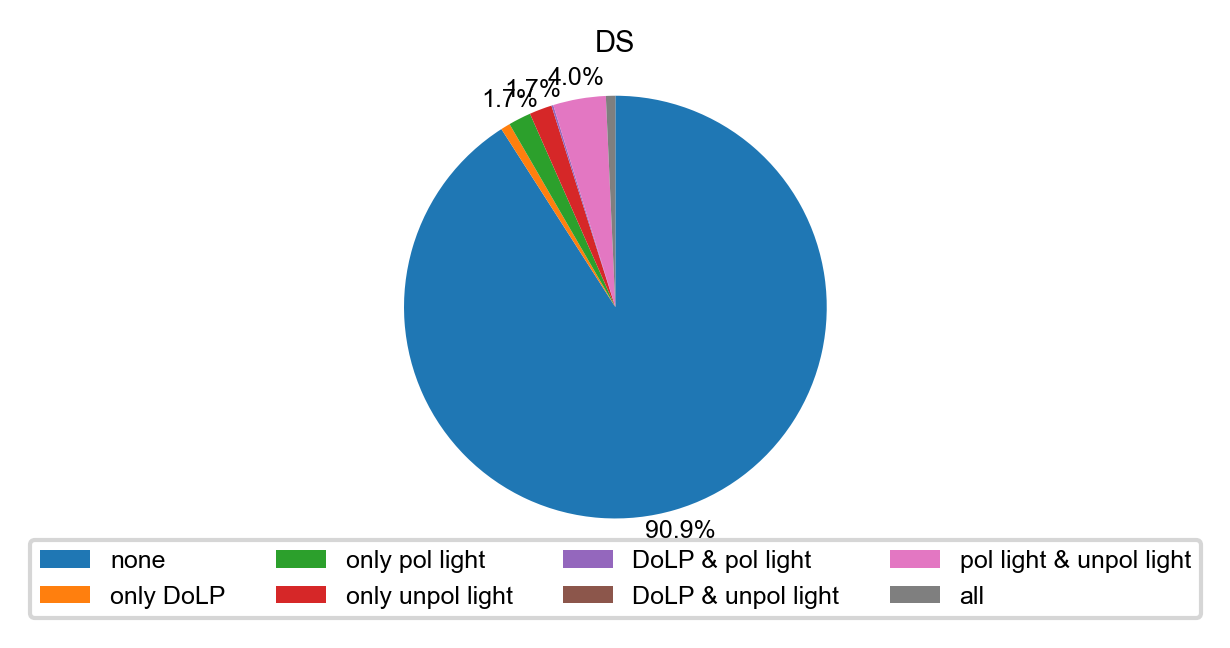

In [57]:
show_pie(R, "ds")

Types: ['none', 'only DoLP', 'only pol light', 'only unpol light', 'DoLP & pol light', 'DoLP & unpol light', 'pol light & unpol light', 'all']
# of cells: [586, 9, 25, 36, 1, 1, 36, 1]
Percentage: [84.31654676258992, 1.2949640287769784, 3.597122302158273, 5.179856115107913, 0.14388489208633093, 0.14388489208633093, 5.179856115107913, 0.14388489208633093]


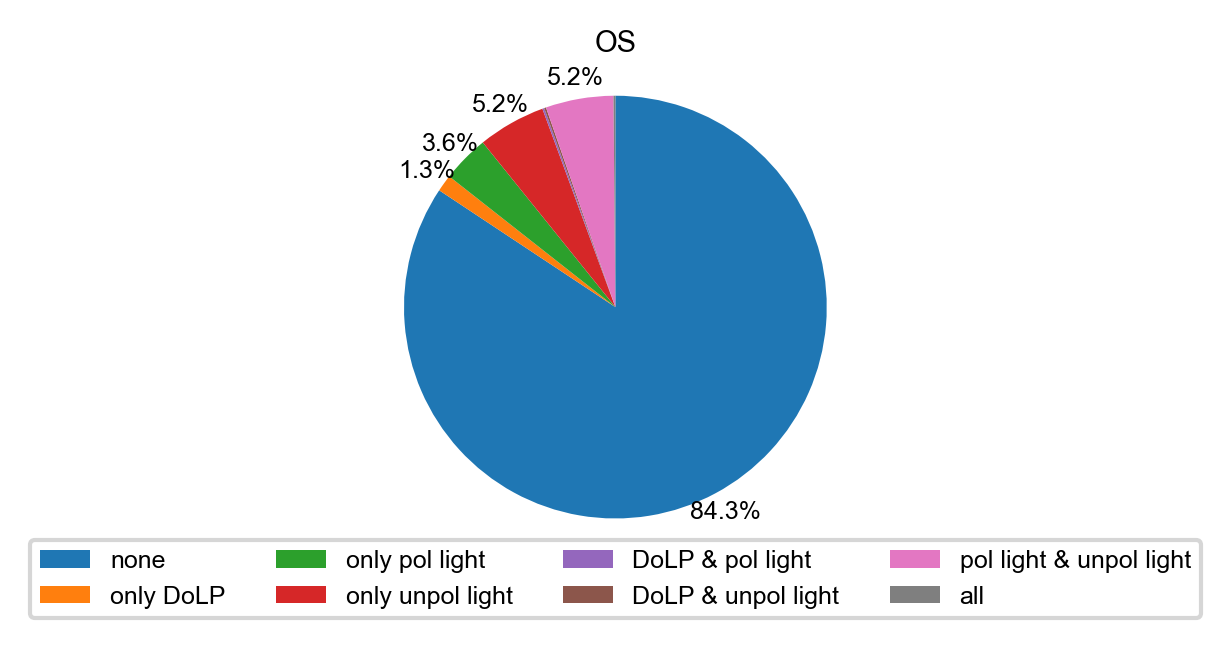

In [58]:
show_pie(R, "os")

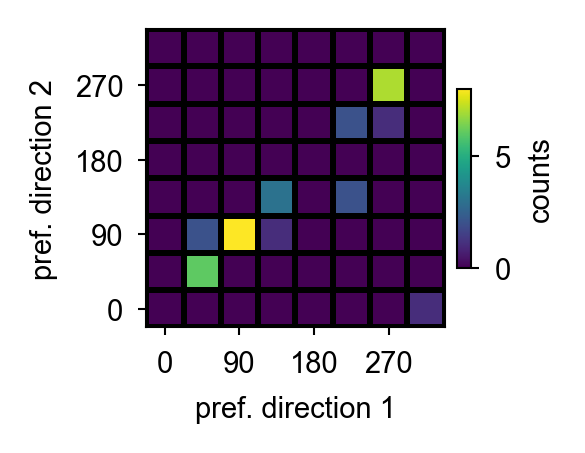

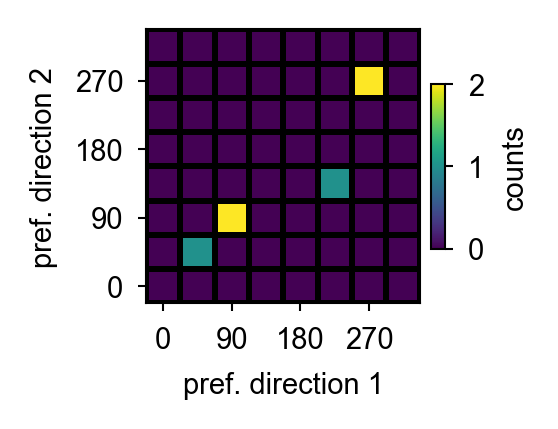

In [59]:
show_two_angles(R, which="ds", figsavename=os.path.join(tmpdir, "pref_direction_pairs_s0_s1.pdf"))
show_two_angles_2(R, which="ds", figsavename=os.path.join(tmpdir, "pref_direction_pairs_s0_s2.pdf"))

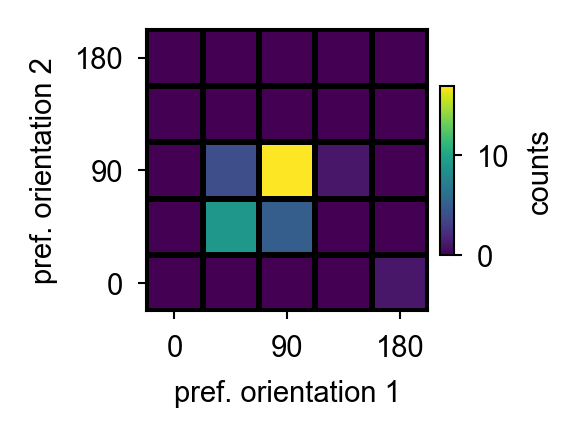

In [52]:
show_two_angles(R, which="os", figsavename=os.path.join(tmpdir, "pref_orientation_pairs.pdf"))

### Distribution of DSI & OSI

In [31]:
def plot_distribution(df, which, figsize=(0.8, 1), figsavename=None):

    if which == "ds":
        k1 = "dsi"
        k2 = "ds_type"
    elif which == "os":
        k1 = "osi"
        k2 = "os_type"

    a, b = [], []
    for i in range(8):
        match = df[df[k2] == i]["cell_id"].unique()
        d = df[df["cell_id"].isin(match)]
        if i == 0:
            dsub = d[d["session"].isin([0,1,2])]
        elif i == 1:
            dsub = d[d["session"]==2]
        elif i == 2:
            dsub = d[d["session"]==1]
        elif i == 3:
            dsub = d[d["session"].isin([0,1])]
        elif i == 4:
            dsub = d[d["session"]==0]
        elif i == 5:
            dsub = d[d["session"].isin([0,2])]
        elif i == 6:
            dsub = d[d["session"].isin([1,2])]
        elif i == 7:
            dsub = d[d["session"].isin([0,1,2])]
        v = dsub.groupby("cell_id")[k1].mean().tolist()
        if len(v) > 0:
            a.append(v)
            if i in [1,2,3,4,5,6,7]:
                b.append(v)

    a = np.concatenate(a) if len(a) > 0 else np.array([])
    b = np.concatenate(b) if len(b) > 0 else np.array([])
    print(a.size)
    print(b.size)

    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    h1, x1 = np.histogram(a, bins=16, range=[0,0.75])
    h2, x2 = np.histogram(b, bins=16, range=[0,0.75])

    ax.bar(x1[:-1], h1, width=np.diff(x1), align="center", color="gray", alpha=1)
    ax.bar(x2[:-1], h2, width=np.diff(x2), align="center", color="orange", alpha=1)
    if which == "ds":
        ax.set_xlabel("gDSI")
    elif which == "os":
        ax.set_xlabel("gOSI")
    ax.set_ylabel("Num. cells")
    ax.set_xlim(0, 0.75)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

def plot_angle_distribution1(df, which):
    if which == "ds":
        k1 = "ang_dsi"
        k2 = "ds_type"
        k3 = "dsi"
    elif which == "os":
        k1 = "ang_osi"
        k2 = "os_type"
        k3 = "osi"

    a = []
    for n in df["cell_id"].unique():
        d = df[df["cell_id"] == n].reset_index()
        i = d.loc[0, k2]
        if i == 0:
            dsub = None
        elif i == 1:
            dsub = d[d["session"]==2]
        elif i == 2:
            dsub = d[d["session"]==1]
        elif i == 3:
            dsub = d[d["session"].isin([0,1])]
        elif i == 4:
            dsub = d[d["session"]==0]
        elif i == 5:
            dsub = d[d["session"].isin([0,2])]
        elif i == 6:
            dsub = d[d["session"].isin([1,2])]
        elif i == 7:
            dsub = d[d["session"].isin([0,1,2])]
        if dsub is not None:
            v = dsub.loc[dsub[k3].idxmax(), k1]
            a.append(v)

    if which == "ds":
        edges = np.arange(-22.5, 360, 45)
    elif which == "os":
        edges = np.arange(-22.5, 180, 45)
    h, bin_edges = np.histogram(a, bins=edges)
    bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

    fig, ax = plt.subplots(figsize=(2,1), dpi=300)
    ax.bar(bin_centers, h, width=40, color="gray", align="center")
    ax.set_xlabel("Angle")
    ax.set_ylabel("Num. cells")
    ax.set_xticks(bin_centers)
    for sp in ["top", "right"]:
        ax.spines[sp].set_visible(False)
    plt.show()

def plot_angle_distribution2(df, which, offset=None, r_max=None, step=5, figsavename=None):
    if which == "ds":
        k1 = "ang_dsi"
        k2 = "ds_type"
        k3 = "dsi"
    elif which == "os":
        k1 = "ang_osi"
        k2 = "os_type"
        k3 = "osi"

    a = []
    for n in df["cell_id"].unique():
        d = df[df["cell_id"] == n].reset_index()
        i = d.loc[0, k2]
        if i == 0:
            dsub = None
        elif i == 1:
            dsub = d[d["session"]==2]
        elif i == 2:
            dsub = d[d["session"]==1]
        elif i == 3:
            dsub = d[d["session"].isin([0,1])]
        elif i == 4:
            dsub = d[d["session"]==0]
        elif i == 5:
            dsub = d[d["session"].isin([0,2])]
        elif i == 6:
            dsub = d[d["session"].isin([1,2])]
        elif i == 7:
            dsub = d[d["session"].isin([0,1,2])]
        if dsub is not None:
            v = dsub.loc[dsub[k3].idxmax(), k1]
            a.append(v)

    if which == "ds":
        edges = np.arange(-22.5, 360, 45)
    elif which == "os":
        edges = np.arange(-22.5, 180, 45)
    h, bin_edges = np.histogram(a, bins=edges)
    bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
    bin_centers_rad = np.deg2rad(bin_centers)
    if offset is None:
        offset = h.max() * 0.25
    if r_max is None:
        r_max = h.max() * 1.1
    if which == "ds":
        step = 5  # radial tick interval
    else:
        step = 10

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(1, 1), dpi=300)
    bars = ax.bar(bin_centers_rad, h, bottom=offset, width=np.deg2rad(40),
                  color='gray', lw=0, align='center', zorder=10)
    theta = np.linspace(0, 2 * np.pi, 500)
    ax.plot(theta, [offset]*len(theta), color='black', linewidth=0.5)

    ax.yaxis.grid(False)
    ax.xaxis.grid(False)
    ax.set_yticklabels([])

    # Draw custom concentric rings starting from offset
    r_ticks = np.arange(offset + step, r_max, step)
    theta = np.linspace(0, 2*np.pi, 500)
    for (k, r) in enumerate(r_ticks):
        ax.plot(theta, [r]*len(theta), color='darkgray', linestyle='--', linewidth=0.5)
        if r_ticks.size > 4:
            if k % 3 == 0:
                ax.text(np.deg2rad(0), r, f"{int(r-offset)}", ha='center', va='bottom', fontsize=6)
        else:
            ax.text(np.deg2rad(0), r, f"{int(r-offset)}", ha='center', va='bottom', fontsize=6)

    if which == "os":
        ax.set_theta_zero_location('E')
        ax.set_theta_direction(-1)
        ax.set_thetamin(0)
        ax.set_thetamax(155)
        ax.set_xticks(np.deg2rad([0, 45, 90, 135]))
    else:
        ax.set_theta_zero_location('E')
        ax.set_theta_direction(-1)
        ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
    ax.tick_params(pad=0)

    if figsavename is not None:
        plt.savefig(figsavename, bbox_inches='tight')
    plt.show()

695
63


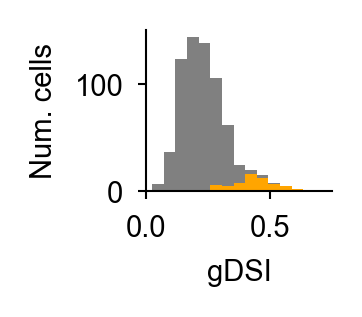

In [32]:
plot_distribution(R, "ds", figsize=(0.8, 0.7), figsavename=os.path.join(tmpdir, "gDSI_distribution.pdf"))

695
109


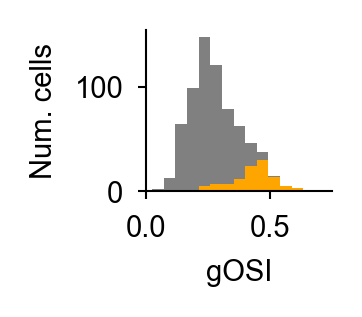

In [33]:
plot_distribution(R, "os", figsize=(0.8, 0.7), figsavename=os.path.join(tmpdir, "gOSI_distribution.pdf"))

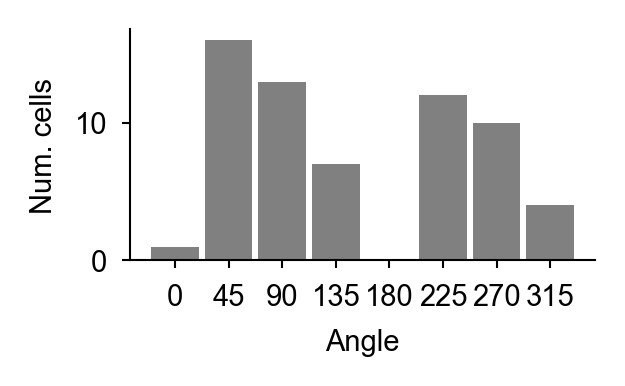

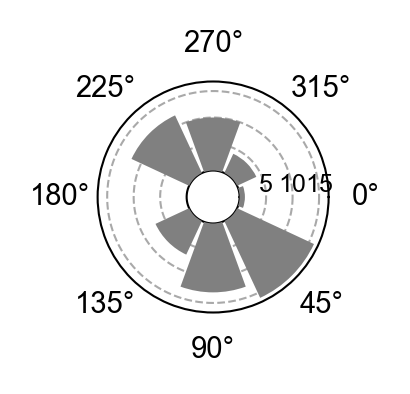

In [34]:
plot_angle_distribution1(R, "ds")
plot_angle_distribution2(R, "ds", offset=5, r_max=22, step=5, figsavename=os.path.join(tmpdir, "DS_angle_distribution.pdf"))

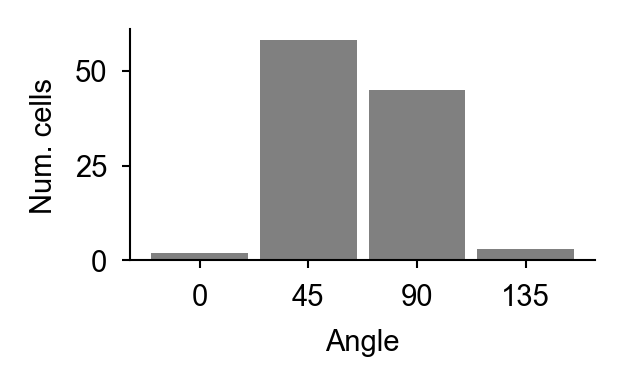

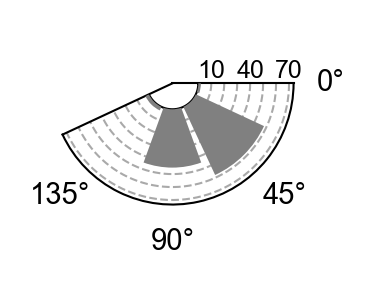

In [35]:
plot_angle_distribution1(R, "os")
plot_angle_distribution2(R, "os", offset=20, r_max=91, step=10, figsavename=os.path.join(tmpdir, "OS_angle_distribution.pdf"))

In [36]:

def plot_grating_response_combined(df, neuron_id, tf, sf, stimulus_train, onset, offset, params: FigParams, ymin1=-0.05, ymax1=0.25, ymin2=-0.05, ymax2=0.25):
    oris = df.index.get_level_values("ori").unique()
    oris = oris.sort_values()
    time = df.index.get_level_values("time").unique() / 1000
    dt = time[1] - time[0]

    fig = plt.figure(figsize=params.size, dpi=params.dpi)
    gs = gridspec.GridSpec(5, len(oris)+2, wspace=0.2,
                           height_ratios=[0.2, 0.1, 1, 1, 1],
                           width_ratios=[1]*9+[1.5])

    # shoow arrows
    for (k, o) in enumerate(oris):
        ax = fig.add_subplot(gs[0, k+1])
        dx, dy = 0.5 * np.cos(np.deg2rad(-o)), 0.5 * np.sin(np.deg2rad(-o))
        ax.arrow(-dx, -dy, 2*dx, 2*dy, head_width=0.4, head_length=0.3, fc='k', ec='k')
        ax.set_xlim([-1.2,1.2])
        ax.set_ylim([-1.2,1.2])
        ax.set_aspect("equal")
        ax.axis("off")

    # show a stimulus train
    for (k, o) in enumerate(oris):
        ax = fig.add_subplot(gs[1, k+1])
        t2 = np.linspace(time[0], time[-1], stimulus_train.size) / 1000
        ax.plot(t2, stimulus_train, color="gray", lw=1)
        ax.axis("off")
        ax.set_xlim([t2[0], t2[-1]])
        ax.set_ylim([-0.25, 1.25])

    # show signals
    df1 = df.xs(neuron_id, level="neuron")
    time_mask = (df1.index.get_level_values("time") >= onset) & (df1.index.get_level_values("time") < offset)
    df2 = df1[time_mask]
    data = []
    for s in range(3):
        responses = []
        for (k, o) in enumerate(oris):
            ax = fig.add_subplot(gs[s+2, k+1])
            df_filtered2 = df2.xs((s, sf, tf, o), level=["session", "sf", "tf", "ori"])
            mat = df_filtered2.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
            R = np.mean(mat, axis=1)
            responses.append(R)
            df_filtered1 = df1.xs((s, sf, tf, o), level=["session", "sf", "tf", "ori"])
            mat1 = df_filtered1.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
            mean = np.nanmean(mat1, axis=0)
            error = np.nanstd(mat1, axis=0)
            mean = ndi.uniform_filter1d(mean, size=4)
            error = ndi.uniform_filter1d(error, size=4)
            ax.plot(time, mean, color="k", linewidth=1, zorder=100)
            # ax.fill_between(time, mean - error, mean + error, color="k", alpha=0.2, linewidth=0, antialiased=True)
            for row in mat1:
                if not np.isnan(row).any():
                    ax.plot(time, ndi.uniform_filter1d(row, size=4), alpha=0.06, color="k", linewidth=0.5)
            ax.set_ylim([ymin1, ymax1])
            ax.set_xlim([time[0], time[-1]])
            ax.axis("off")
            # ax.set_xticks([])
            # ax.set_yticks([])
            # ax.set_xlabel("")
            # ax.set_ylabel("")
            # for sp in ["top", "right", "bottom", "left"]:
            #     ax.spines[sp].set_visible(False)
        responses = np.array(responses)
        data.append({
            "session": s,
            "mean": np.nanmean(responses, axis=1),
            "max": np.nanmax(responses, axis=1),
            "std": np.nanstd(responses, axis=1)
        })

    # show radar
    for s in range(3):
        ax = fig.add_subplot(gs[s+2, 9], polar=True)
        oris_rad = np.radians(oris)
        oris_rad = (-1) * oris_rad
        oris_rad = np.append(oris_rad, oris_rad[0])
        mean = data[s]["mean"]
        mean = np.append(mean, mean[0]) # add the first element to the end to close the loop
        # error = data[s]["std"]
        # error = np.append(error, error[0]) # add the first element to the end to close the loop
        # sem = error / np.sqrt(responses.shape[1])
        # prevent negative
        mean[mean < ymin2] = ymin2
        ax.plot(oris_rad, mean, color="k", linewidth=1, zorder=100)
        # ax.fill_between(oris_rad, mean - sem, mean + sem, color="k", alpha=0.3)
        # ax.set_theta_zero_location("E")  # Set 0 degrees at the right
        # ax.set_theta_direction(-1)  # Clockwise direction
        ax.set_yticklabels([])  # Remove radial ticks
        ax.set_xticklabels([])
        ax.grid(False)
        ax.set_ylim([ymin2, ymax2])
        ax.spines['polar'].set_color('gray')
        # Draw custom concentric rings starting from offset
        r_ticks = np.arange(ymin2 + 0.05, ymax2, 0.05)
        theta = np.linspace(0, 2*np.pi, 360)
        for (k, r) in enumerate(r_ticks):
            ax.plot(theta, [r]*len(theta), color='lightgray', linestyle='--', linewidth=0.5)

    # draw scale bar
    scalebar_axis = fig.add_subplot(gs[2,0])
    scalebar_axis.plot([-1, 0], [ymin1+0.1, ymin1+0.1], color='black', lw=2)
    scalebar_axis.text(-0.5, ymin1+0.1, '1 sec', color='black', ha='left', va='bottom', rotation=0)
    scalebar_axis.plot([-1,-1], [ymin1+0.1, ymin1+0.3], color='k', lw=2)
    scalebar_axis.text(-0.5, ymin1+0.1, '0.2 $\Delta$F/F', color='k', ha='left', va='bottom', rotation=90)
    scalebar_axis.set_xlim(time[0], time[-1])
    scalebar_axis.set_ylim(ymin1, ymax1)
    scalebar_axis.axis("off")

    if params.savename is not None:
        plt.savefig(params.savename, bbox_inches='tight')
    plt.show()


### Plot responses of example neurons

In [37]:
dt = 1e-2
stimulus = np.zeros(int(6.5/dt), dtype=np.float32)
stimulus[0:int(2.0/dt)] = 0
stimulus[int(2.0/dt):int(4.5/dt)] = 1
stimulus[int(4.5/dt):int(6.5/dt)] = 0

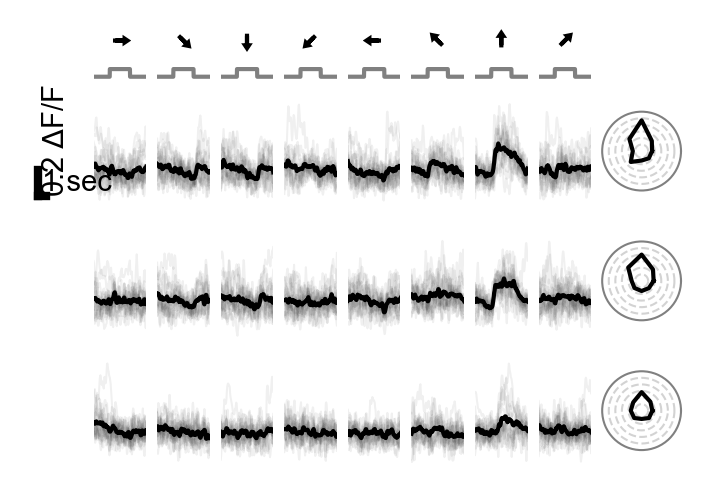

1 68 0 0.45332909591338333 90 0.1508505194549549 0.052110091743119265
1 68 0 0.5579046296292277 270 0.1508505194549549 0.0089
1 68 1 0.43147626663450583 90 0.12313136301236595 0.06275229357798165
1 68 1 0.7780441086402271 270 0.12313136301236595 0.0
1 68 2 0.19097854178404122 90 0.0944214687735962 0.6458715596330276
1 68 2 0.4657435003961484 270 0.0944214687735962 0.0466


In [38]:
# DS type 7 - DS to all
rec = 1
nid = 68
d = E.xs(rec, level="recording")
plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                               params=FigParams(size=[2.8, 1.9], dpi=300, savename=os.path.join(tmpdir, f"{rec}_{nid:03d}.pdf")),
                               ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

d = R[(R["recording"] == rec) & (R["neuron"] == nid)]
for idx, row in d.iterrows():
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])

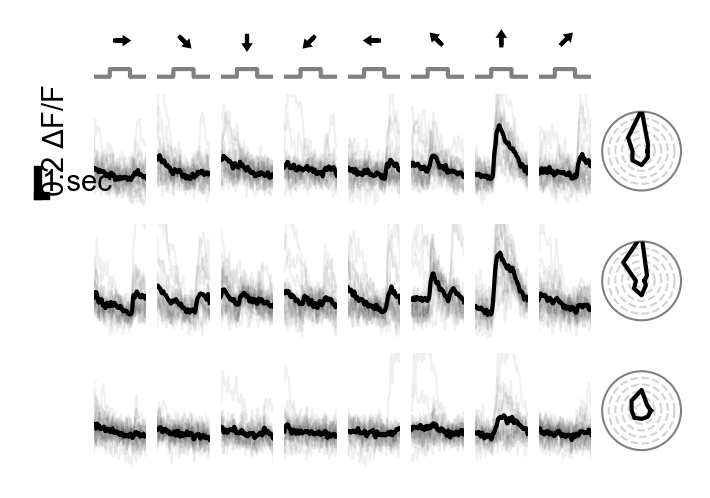

1 77 0 0.5828202119343769 90 0.23269398844112252 0.0066055045871559635
1 77 0 0.49786761892369297 270 0.23269398844112252 0.0295
1 77 1 0.6844963724321638 90 0.2530426588029452 0.0009174311926605505
1 77 1 0.6371627633853878 270 0.2530426588029452 0.0011
1 77 2 0.4076469278507497 90 0.09510690121219081 0.13990825688073394
1 77 2 0.6072596686729586 270 0.09510690121219081 0.0073


In [39]:
# DS type 7 - DS to all
rec = 1
nid = 77
d = E.xs(rec, level="recording")
plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                               params=FigParams(size=[2.8, 1.9], dpi=300, savename=os.path.join(tmpdir, f"{rec}_{nid:03d}.pdf")),
                               ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

d = R[(R["recording"] == rec) & (R["neuron"] == nid)]
for idx, row in d.iterrows():
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])

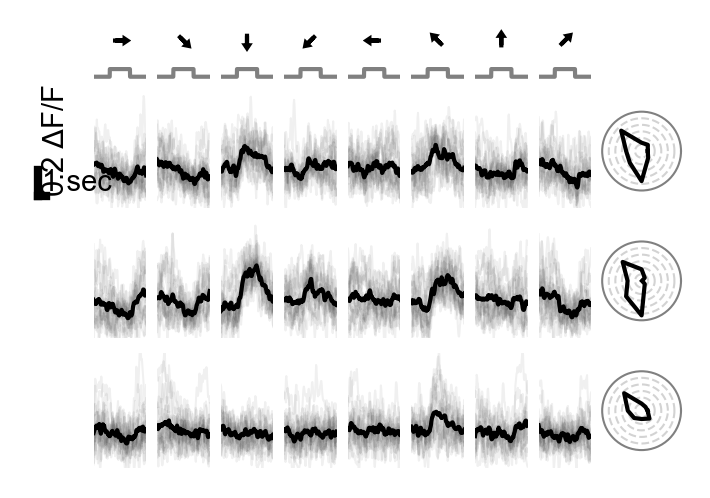

1 1 0 0.29027194079739155 90 0.15317065059174276 0.29908256880733947
1 1 0 0.43530823966562204 90 0.15317065059174276 0.0524
1 1 1 0.3420385512625573 90 0.19680469036890036 0.16990825688073394
1 1 1 0.49983155970809934 90 0.19680469036890036 0.0202
1 1 2 0.5403816533911941 45 0.08943810776546489 0.015045871559633028
1 1 2 0.5638905020115308 225 0.08943810776546489 0.0086


In [40]:
# strance cell - peak disapper in DoLP gratings
rec = 1
nid = 1
d = E.xs(rec, level="recording")
plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                               params=FigParams(size=[2.8, 1.9], dpi=300, savename=os.path.join(tmpdir, f"{rec}_{nid:03d}.pdf")),
                               ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

d = R[(R["recording"] == rec) & (R["neuron"] == nid)]
for idx, row in d.iterrows():
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])

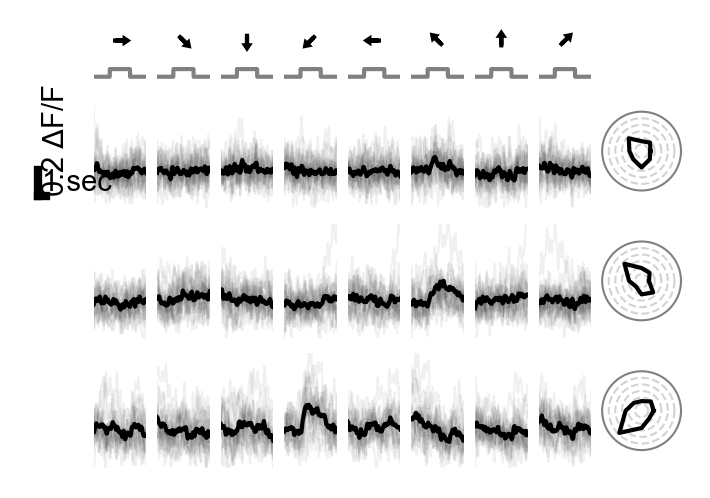

5 40 0 0.26467763918837156 45 0.06657042688684299 0.3922
5 40 0 0.26557529556273274 225 0.06657042688684299 0.3781
5 40 1 0.471124275420839 45 0.07684086783461896 0.0415
5 40 1 0.2346804466931257 225 0.07684086783461896 0.4785
5 40 2 0.5115594060851606 135 0.12021591482282568 0.0181
5 40 2 0.602364824824539 135 0.12021591482282568 0.0034


In [41]:
# DS in polarization
rec = 5
nid = 40
d = E.xs(rec, level="recording")
plot_grating_response_combined(d, nid, 3, 0.00850, stimulus, 0, 2500,
                               params=FigParams(size=[2.8, 1.9], dpi=300, savename=os.path.join(tmpdir, f"{rec}_{nid:03d}.pdf")),
                               ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

d = R[(R["recording"] == rec) & (R["neuron"] == nid)]
for idx, row in d.iterrows():
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])

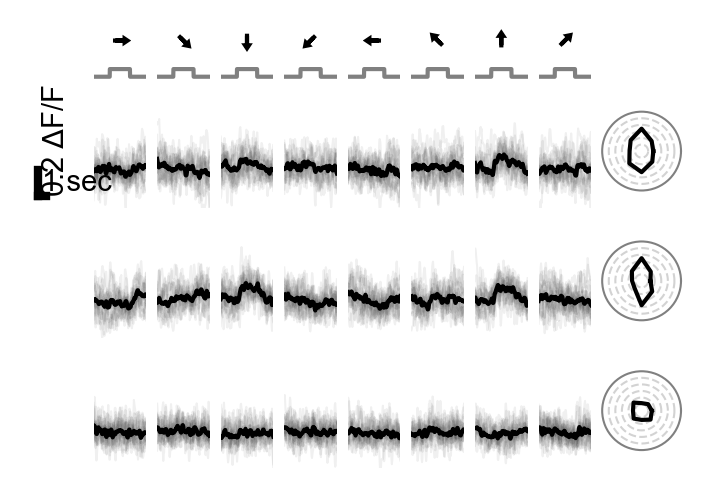

1 113 0 0.5523465070923761 90 0.08441966323634743 0.0001834862385321101
1 113 0 0.07941867973249218 270 0.08441966323634743 0.8845
1 113 1 0.6287211381735541 90 0.12400243899859874 0.0013761467889908258
1 113 1 0.049717221288666735 90 0.12400243899859874 0.9667
1 113 2 0.21269630799194186 45 0.060603561493958506 0.5289908256880734
1 113 2 0.20634552830833774 45 0.060603561493958506 0.5496


In [42]:
# OS
rec = 1
nid = 113
d = E.xs(rec, level="recording")
plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                               params=FigParams(size=[2.8, 1.9], dpi=300, savename=os.path.join(tmpdir, f"{rec}_{nid:03d}.pdf")),
                               ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

d = R[(R["recording"] == rec) & (R["neuron"] == nid)]
for idx, row in d.iterrows():
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])

In [ ]:
df = R[(R["ds_type"].isin([6])) & (R["session"] == 0)]
for idx, row in df.iterrows():
    rec = row["recording"]
    nid = row["neuron"]
    d = E.xs(rec, level="recording")
    print(rec, nid, row["session"], row["dsi"], row["ang_dsi"], row["qi"], row["pval_dsi"])
    if rec in [0,1,2,3]:
        plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)
    else:
        print
        plot_grating_response_combined(d, nid, 3, 0.0085, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

In [ ]:
df = R[(R["os_type"].isin([6])) & (R["session"] == 0)]
for idx, row in df.iterrows():
    rec = row["recording"]
    nid = row["neuron"]
    d = E.xs(rec, level="recording")
    print(rec, nid, row["session"], row["osi"], row["ang_osi"], row["qi"], row["pval_osi"])
    if rec in [0,1,2,3]:
        plot_grating_response_combined(d, nid, 3, 0.00425, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)
    else:
        print
        plot_grating_response_combined(d, nid, 3, 0.0085, stimulus, 0, 2500,
                                       params=FigParams(size=[4, 2.5], dpi=300),
                                       ymin1=-0.3, ymax1=0.6, ymin2=-0.1, ymax2=0.2)

In [ ]:
# df = R[(R["ds_type"].isin([4])) & (R["session"] == 0)]

# for idx, row in df.iterrows():
#     rec = row["recording"]
#     nid = row["neuron"]
#     d = E.xs(rec, level="recording")
#     for s in [0,1]:
#         print(rec, nid, row["session"], row["dsi"], row["qi"], row["pval_dsi"])
#         plot_grating_response(d, nid, row["session"], 3, 0.00425, stimulus_train=stimulus, params=FigParams(size=[6, 2], dpi=300), vmin=-0.1, vmax=0.3)

### OS cells, difference between 1st and 2nd strongest peaks

In [ ]:
def get_response(df, neuron_id, session, tf, sf, onset, offset):
    angles = df.index.get_level_values("ori").unique()
    angles = angles.sort_values()
    df1 = df.xs(neuron_id, level="neuron")
    time_mask = (df1.index.get_level_values("time") >= onset) & (df1.index.get_level_values("time") < offset)
    df2 = df1[time_mask]
    responses = []
    for (k, o) in enumerate(angles):
        df_filtered = df2.xs((session, sf, tf, o), level=["session", "sf", "tf", "ori"])
        mat = df_filtered.reset_index().pivot(index="trial", columns="time", values="y").to_numpy()
        r = np.mean(mat, axis=1)
        responses.append(r)
    responses = np.array(responses)
    responses = np.nanmean(responses, axis=1)
    rank = np.argsort(responses)
    ang1 = angles[rank[0]]
    ang2 = angles[rank[1]]
    return ang1, ang2

In [ ]:
# df = R[(R["os_type"].isin([2,4,6]))]
df = R[(R["os_type"].isin([1,2,3,4,6,7])) & ~(R["ds_type"].isin([1,2,3,4,6,7]))]

data = []
for idx, row in df.iterrows():
    if row["flag_osi"]:
        rec = row["recording"]
        nid = row["neuron"]
        session = row["session"]
        d = E.xs(rec, level="recording")
        if rec in [0,1,2,3]:
            a, b = get_response(d, nid, session, 3, 0.00425, 0, 2500)
        else:
            a, b = get_response(d, nid, session, 3, 0.0085, 0, 2500)
        data.append(np.abs(a-b))

data = np.array(data)

In [ ]:
edges = np.arange(-22.5, 225, 45)
h, bin_edges = np.histogram(data, bins=edges)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
bin_centers_rad = np.deg2rad(bin_centers)

fig, ax = plt.subplots(figsize=(2,1), dpi=300)
ax.bar(bin_centers, h, width=40, color="gray", align="center")
ax.set_xlabel("Angle")
ax.set_ylabel("Num. cells")
ax.set_xticks(bin_centers)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

### Copy data to bucket

In [45]:
savedir = "/bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/plots"
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/plots
cp -r /flash/ReiterU/tmp/tomo_SPUUOBIVRRVW/* /bucket/ReiterU/OLdev/analysis/20250409_IGL_DS_OS/plots


In [73]:
match = [k for k, v in os_type_map.items() if v in [6]] # both
df = R[R["cell_id"].isin(match)]
x1 = df[df["session"]==0]["osi"]
y1 = df[df["session"]==1]["osi"]

match = [k for k, v in os_type_map.items() if v in [2]] # only pol
df = R[R["cell_id"].isin(match)]
x2 = df[df["session"]==0]["osi"]
y2 = df[df["session"]==1]["osi"]

match = [k for k, v in os_type_map.items() if v in [4]] # only unpol
df = R[R["cell_id"].isin(match)]
x3 = df[df["session"]==0]["osi"]
y3 = df[df["session"]==1]["osi"]

match = [k for k, v in os_type_map.items() if v in [0]] # only unpol
df = R[R["cell_id"].isin(match)]
x4 = df[df["session"]==0]["osi"]
y4 = df[df["session"]==1]["osi"]

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
cm = plt.get_cmap("tab10")
ax.scatter(x4, y4, s=3, color="gray", lw=0, alpha=0.8)
ax.scatter(x1, y1, s=3, color=cm(0), lw=0, alpha=0.8)
ax.scatter(x2, y2, s=3, color=cm(1), lw=0, alpha=0.8)
ax.scatter(x3, y3, s=3, color=cm(2), lw=0, alpha=0.8)

ax.set_xlabel("gDSI - unpol")
ax.set_ylabel("gDSI - pol")
ax.set_xlim(0,0.8)
ax.set_ylim(0,0.8)

plt.show()

NameError: name 'os_type_map' is not defined

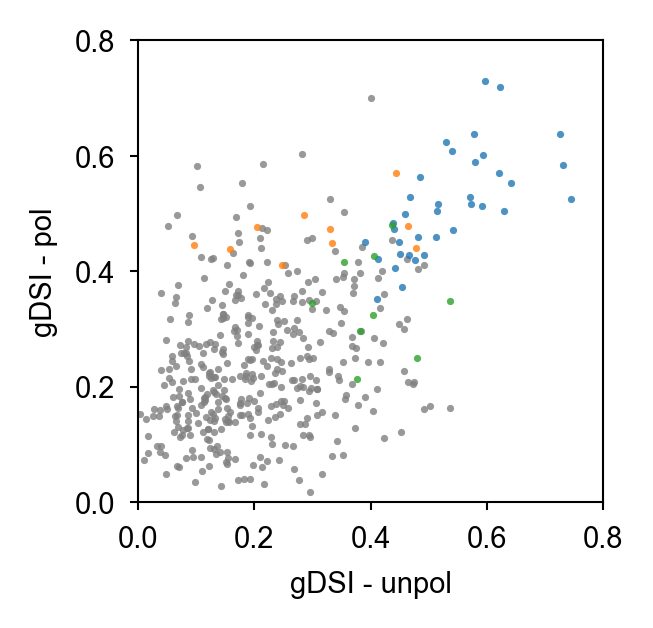

In [31]:
match = [k for k, v in ds_type_map.items() if v in [6]] # both
df = R[R["cell_id"].isin(match)]
x1 = df[df["session"]==0]["dsi"]
y1 = df[df["session"]==1]["dsi"]

match = [k for k, v in ds_type_map.items() if v in [2]] # only pol
df = R[R["cell_id"].isin(match)]
x2 = df[df["session"]==0]["dsi"]
y2 = df[df["session"]==1]["dsi"]

match = [k for k, v in ds_type_map.items() if v in [4]] # only unpol
df = R[R["cell_id"].isin(match)]
x3 = df[df["session"]==0]["dsi"]
y3 = df[df["session"]==1]["dsi"]

match = [k for k, v in ds_type_map.items() if v in [0]] # only unpol
df = R[R["cell_id"].isin(match)]
x4 = df[df["session"]==0]["dsi"]
y4 = df[df["session"]==1]["dsi"]

fig, ax = plt.subplots(figsize=(2,2), dpi=300)
cm = plt.get_cmap("tab10")
ax.scatter(x4, y4, s=3, color="gray", lw=0, alpha=0.8)
ax.scatter(x1, y1, s=3, color=cm(0), lw=0, alpha=0.8)
ax.scatter(x2, y2, s=3, color=cm(1), lw=0, alpha=0.8)
ax.scatter(x3, y3, s=3, color=cm(2), lw=0, alpha=0.8)

# ax.scatter(x4, y4, s=3, color="gray", lw=0, alpha=0.8)
# ax.scatter(x1, y1, s=3, color="gray", lw=0, alpha=0.8)
# ax.scatter(x2, y2, s=3, color="gray", lw=0, alpha=0.8)
# ax.scatter(x3, y3, s=3, color="gray", lw=0, alpha=0.8)

ax.set_xlabel("gDSI - unpol")
ax.set_ylabel("gDSI - pol")
ax.set_xlim(0,0.8)
ax.set_ylim(0,0.8)

plt.show()